# More Visualizations? Yes, Please!

This notebook covers Parts I through V of the assignment. Parts I through III build three-dimensional visualizations with Matplotlib's mplot3d toolkit. Part IV contains the written answers for the Unity tutorial (the screenshots are uploaded separately), and Part V examines an extended reality data visualization.

**Note on interactivity:** Every plot uses the ipympl backend (`%matplotlib ipympl`), so each figure can be rotated by clicking and dragging inside it. If the backend is not installed, run `python -m pip install ipympl` and then restart JupyterLab.

In [1]:
# Enable interactive (rotatable) Matplotlib figures inside JupyterLab
%matplotlib ipympl

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d

# Larger default fonts so every title, label, and tick is easy to read
plt.rcParams.update({'font.size': 12, 'axes.titlesize': 16, 'axes.labelsize': 13,
                     'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 12})

## Part I: Mathematical 3D Plots

### 3D Line Plot

The line contains 1,000 points. The Z values come from `np.linspace()` (100 to 150), the X values come from a single function, `np.log()`, and the Y values come from a single function, `np.cos()`. Because the natural logarithm of 100 is about 4.6 and the natural logarithm of 150 is about 5.0, the X Axis spans 4.6 to 5.0, while the cosine keeps the Y Axis between -1 and 1.

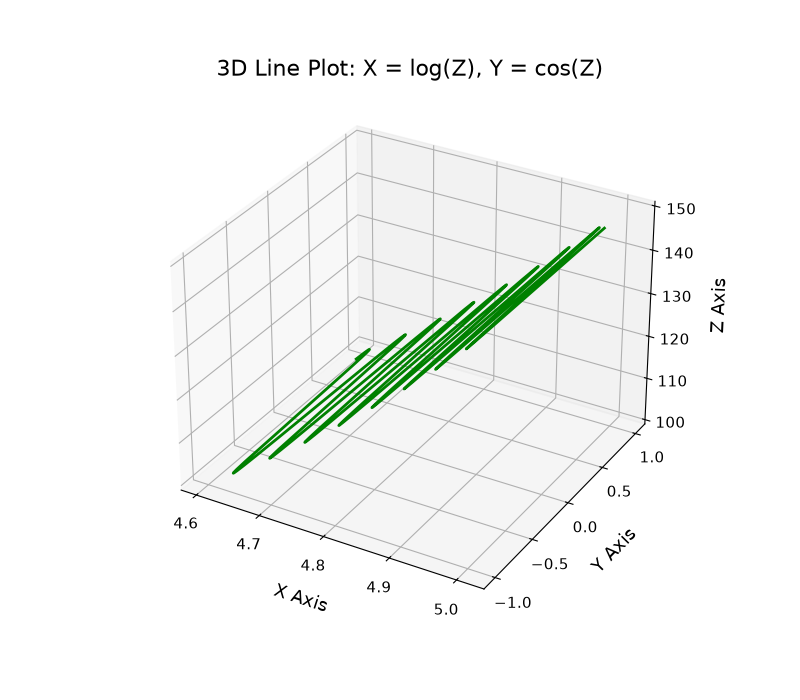

In [2]:
# 1,000 points: one axis from linspace, the other two from a single function each
z = np.linspace(100, 150, 1000)
x = np.log(z)
y = np.cos(z)

fig = plt.figure(figsize=(8, 7))
ax = plt.axes(projection='3d')
ax.plot3D(x, y, z, color='green', linewidth=2)

ax.set_title('3D Line Plot: X = log(Z), Y = cos(Z)')
ax.set_xlabel('X Axis', labelpad=10)
ax.set_ylabel('Y Axis', labelpad=10)
ax.set_zlabel('Z Axis', labelpad=10)
ax.set_xticks([4.6, 4.7, 4.8, 4.9, 5.0])
ax.set_yticks([-1.0, -0.5, 0.0, 0.5, 1.0])
plt.show()

The interactive plot above can be rotated freely. The figure below uses `view_init()` to reproduce the three angles pictured in the assignment: the Y Axis facing the viewer, an oblique view of all three axes, and the X Axis facing the viewer.

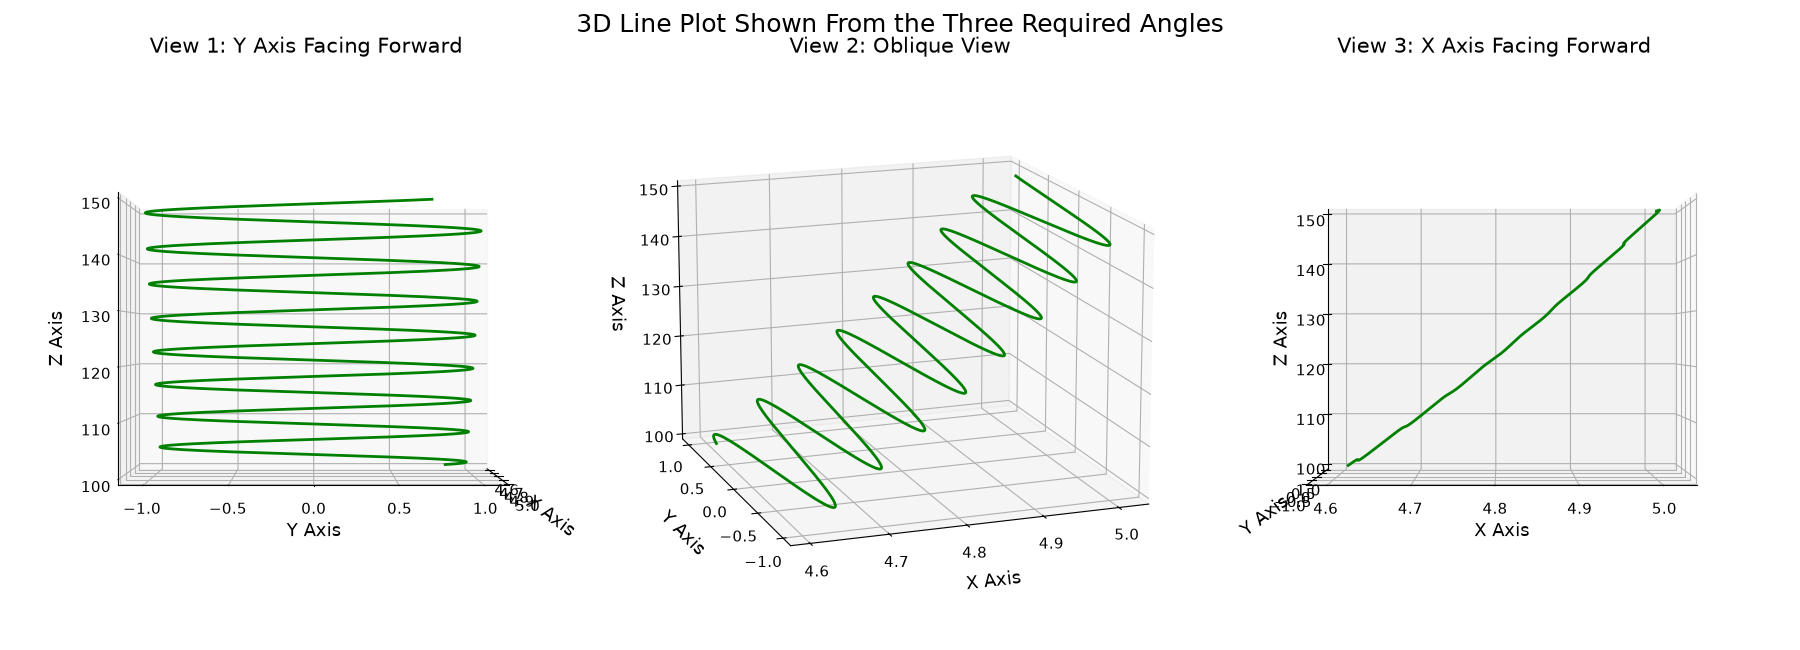

In [3]:
# Reproduce the three required viewing angles (elevation, azimuth)
angles = [(0, 0, 'View 1: Y Axis Facing Forward'),
          (15, -110, 'View 2: Oblique View'),
          (0, -90, 'View 3: X Axis Facing Forward')]

fig = plt.figure(figsize=(18, 6.5))
for i, (elev, azim, label) in enumerate(angles, start=1):
    ax = fig.add_subplot(1, 3, i, projection='3d')
    ax.plot3D(x, y, z, color='green', linewidth=2)
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(label, fontsize=15)
    ax.set_xlabel('X Axis', labelpad=10)
    ax.set_ylabel('Y Axis', labelpad=10)
    ax.set_zlabel('Z Axis', labelpad=10)
    ax.set_xticks([4.6, 4.7, 4.8, 4.9, 5.0])
    ax.set_yticks([-1.0, -0.5, 0.0, 0.5, 1.0])
fig.suptitle('3D Line Plot Shown From the Three Required Angles', fontsize=18)
plt.tight_layout()
plt.show()

### 3D Contour Plot

The data starts with 500 evenly spaced values of t between 0 and 30. X is the cosine of t, Y is the sine of t, and Z is the sine of the square root of X squared plus Y squared, calculated over a meshgrid of X and Y. The plot uses 50 contour levels and the viridis colormap.

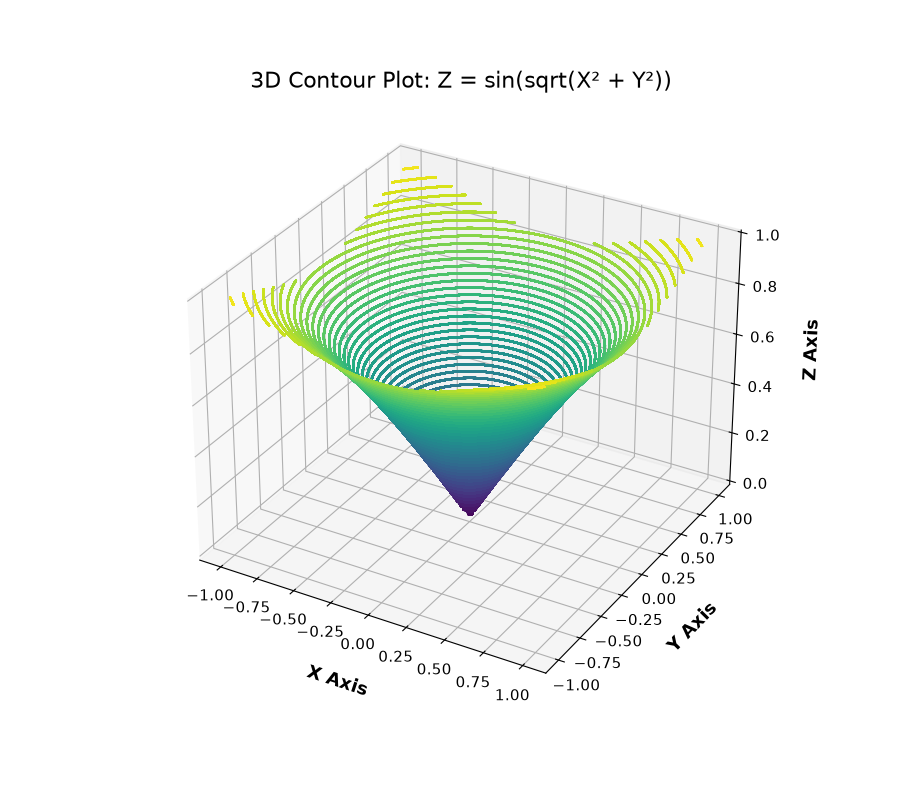

In [4]:
t = np.linspace(0, 30, 500)
x_c = np.cos(t)
y_c = np.sin(t)
X, Y = np.meshgrid(x_c, y_c)
Z = np.sin(np.sqrt(X ** 2 + Y ** 2))

fig = plt.figure(figsize=(9, 8))
ax = plt.axes(projection='3d')
ax.contour3D(X, Y, Z, 50, cmap='viridis')

ax.set_title('3D Contour Plot: Z = sin(sqrt(X\u00b2 + Y\u00b2))')
ax.set_xlabel('X Axis', labelpad=13, fontweight='bold')
ax.set_ylabel('Y Axis', labelpad=13, fontweight='bold')
ax.set_zlabel('Z Axis', labelpad=13, fontweight='bold')
plt.show()

**Shape description:** The contour lines stack into a smooth, upside-down cone that comes to a sharp point at the origin, where Z equals 0, and opens upward and outward as the distance from the center grows. Each ring is a circle because Z depends only on the distance from the center, so every point at the same distance shares the same height. The rings change color from dark purple at the narrow bottom to bright yellow at the wide rim, and a few broken yellow arcs sit above the corners of the grid, where the distance from the center reaches about 1.41 and Z climbs to nearly 1.

**What it resembles:** The plot looks like a funnel or an ice cream cone viewed from above. With its tightly stacked rings, it also resembles a tornado, or a spinning top balanced on its tip.

### Enclosed Surface Plot: Sphere

A sphere's volume is four-thirds times pi times the radius cubed. Solving for a volume of 65,450 cubic units gives a radius of 25, because four-thirds times pi times 25 cubed equals about 65,450. The code below confirms the volume and then draws the sphere with parametric equations.

Radius: 25
Volume check: 65,449.85 cubic units


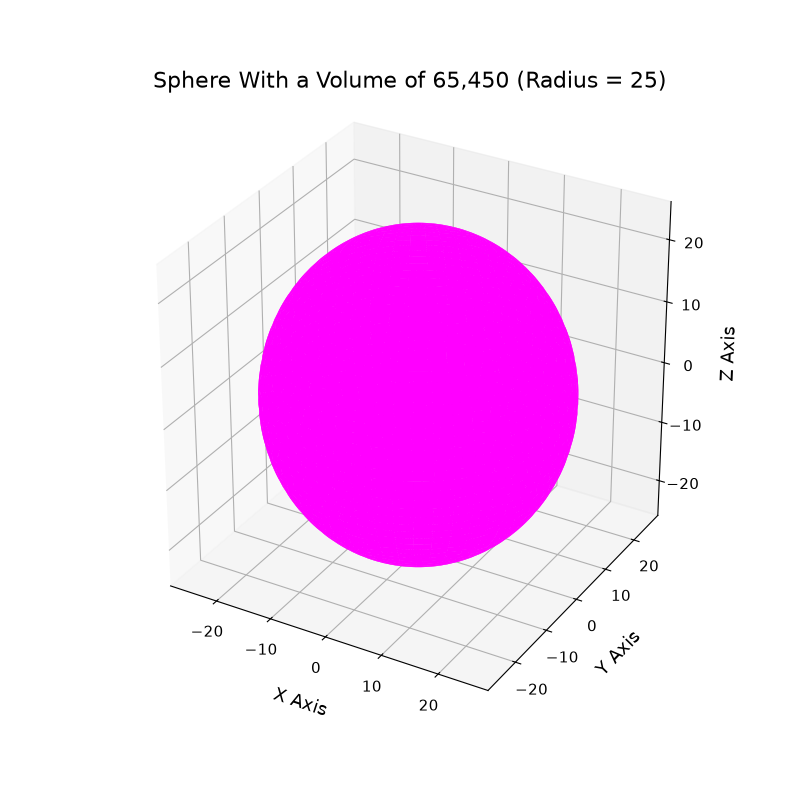

In [5]:
# Solve for the radius that produces a volume of 65,450
target_volume = 65450
r = round((3 * target_volume / (4 * np.pi)) ** (1 / 3))
print(f'Radius: {r}')
print(f'Volume check: {4 / 3 * np.pi * r ** 3:,.2f} cubic units')

# Parametric equations for a sphere
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 100)
xs = r * np.outer(np.cos(u), np.sin(v))
ys = r * np.outer(np.sin(u), np.sin(v))
zs = r * np.outer(np.ones(np.size(u)), np.cos(v))

fig = plt.figure(figsize=(8, 8))
ax = plt.axes(projection='3d')
ax.plot_surface(xs, ys, zs, color='magenta', shade=False)
ax.set_box_aspect((1, 1, 1))

ax.set_title('Sphere With a Volume of 65,450 (Radius = 25)')
ax.set_xlabel('X Axis', labelpad=10)
ax.set_ylabel('Y Axis', labelpad=10)
ax.set_zlabel('Z Axis', labelpad=10)
plt.show()

## Part II: 3D Scatter Plot With Steam Data

The Steam data set stores Price with a leading dollar sign and Metascore with a trailing percent sign, so both columns are cleaned and converted to numbers before plotting. Only the Indie and Simulation game types are kept.

In [6]:
steam = pd.read_csv('steam_games.csv')

# Remove the currency and percent symbols, then convert to numbers
steam['Price'] = steam['Price'].str.replace('$', '', regex=False).str.strip().astype(float)
steam['Metascore'] = steam['Metascore'].str.replace('%', '', regex=False).str.strip().astype(float)

subset = steam[steam['Game_Type'].isin(['Indie', 'Simulation'])]
print(subset['Game_Type'].value_counts())
subset.groupby('Game_Type')[['Price', 'Metascore', 'Average_Hours_Played']].agg(['mean', 'median', 'max']).round(1)

Game_Type
Indie         167
Simulation    100
Name: count, dtype: int64


Price              Metascore              Average_Hours_Played  \
            mean median   max      mean median   max                 mean   
Game_Type                                                                   
Indie       18.5   18.0  60.0      77.2   79.0  93.0                  4.7   
Simulation  22.3   20.0  60.0      77.0   78.0  91.0                  6.0   

                       
           median max  
Game_Type              
Indie         3.0  49  
Simulation    4.0  38

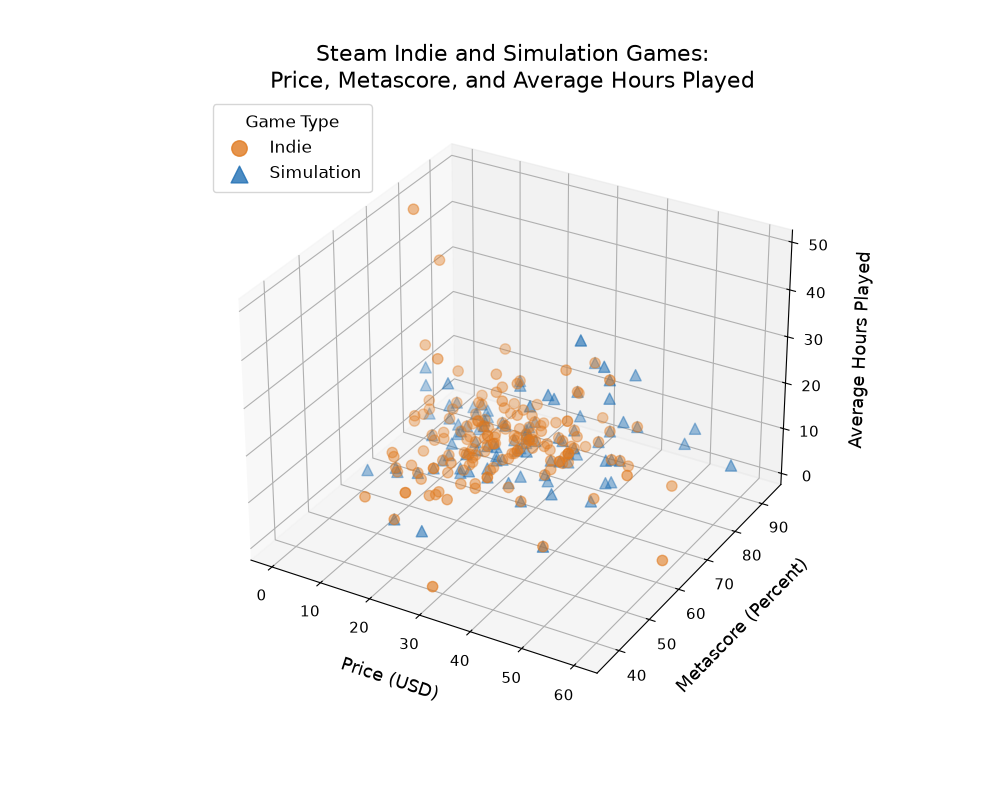

In [7]:
indie = subset[subset['Game_Type'] == 'Indie']
sim = subset[subset['Game_Type'] == 'Simulation']

fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection='3d')
ax.scatter3D(indie['Price'], indie['Metascore'], indie['Average_Hours_Played'],
             color='#E07A1F', marker='o', s=55, alpha=0.8, label='Indie')
ax.scatter3D(sim['Price'], sim['Metascore'], sim['Average_Hours_Played'],
             color='#1F6FB4', marker='^', s=65, alpha=0.8, label='Simulation')

ax.set_title('Steam Indie and Simulation Games:\nPrice, Metascore, and Average Hours Played')
ax.set_xlabel('Price (USD)', labelpad=12)
ax.set_ylabel('Metascore (Percent)', labelpad=12)
ax.set_zlabel('Average Hours Played', labelpad=12)
ax.legend(title='Game Type', borderpad=0.6, markerscale=1.5, loc='upper left')
plt.show()

**Takeaways:**

1. **Most games in both genres hold players for only a few hours.** The points crowd near the floor of the plot. About 77 percent of Indie games and 64 percent of Simulation games average 5 hours of play or less, and the medians are only 3 hours for Indie and 4 hours for Simulation.
2. **Simulation games tend to cost more.** Simulation games average about 22.30 USD, compared with about 18.50 USD for Indie games, and 20 percent of Simulation titles cost more than 30 USD, compared with only 7 percent of Indie titles. Seventy-one percent of Indie games cost less than 20 USD, so the orange circles cluster on the low-price side of the X Axis.
3. **A higher price matters more for Simulation playtime than for Indie playtime.** For Simulation games, price and average hours have a moderate positive correlation of about 0.35, and several of the tallest blue triangles, such as Star Trek Online (38 hours), sit at about 40 USD. For Indie games the correlation is close to zero (about -0.05), and the two longest-played Indie games in the subset, Metin2 (49 hours) and MEDIEVAL KNIGHTMARE (34 hours), are both free.
4. **Critics rate both genres almost equally.** Average Metascores are nearly identical, about 77.2 percent for Indie games and 77.0 percent for Simulation games, so the two groups overlap heavily along the Y Axis. The Indie group has a wider spread, with scores ranging from 37 to 93 percent, compared with 49 to 91 percent for Simulation games.
5. **A strong Metascore does not guarantee long playtime.** Many games scoring 80 percent or higher still average only 1 to 5 hours, which shows that critical approval and long-term player engagement are separate measures of success.

## Part III: 3D Bar Graph With My Own Data

**Data description:** The file `electricity_mix_2025.csv` comes from [Our World in Data's energy data set](https://github.com/owid/energy-data), which compiles electricity statistics from the Energy Institute's Statistical Review of World Energy and Ember. I kept the 2025 values for six large electricity producers (Brazil, China, Germany, India, Japan, and the United States) and six generation sources (coal, gas, nuclear, hydro, wind, and solar).

The file has four variables:

- **country:** the country name (categorical)
- **year:** the data year, 2025 for every row
- **source:** the electricity source (categorical)
- **share_of_electricity_pct:** the percentage of that country's total electricity generation that came from the source (numeric)

The two categorical variables, country and source, become the X Axis and Y Axis, and the numeric share becomes the bar height on the Z Axis.

In [8]:
energy = pd.read_csv('electricity_mix_2025.csv')
energy.pivot(index='country', columns='source', values='share_of_electricity_pct')[
    ['Coal', 'Gas', 'Nuclear', 'Hydro', 'Wind', 'Solar']]

source,Coal,Gas,Nuclear,Hydro,Wind,Solar
country,,,,,,
Brazil,2.29,7.31,2.12,51.78,15.67,11.81
China,54.34,3.16,4.61,13.20,10.73,11.10
Germany,20.61,16.52,0.00,3.91,27.18,17.91
India,70.82,2.33,2.59,8.55,5.00,9.41
Japan,32.05,32.78,9.14,7.18,1.25,9.81
United States,16.31,39.99,17.36,5.35,10.28,8.60


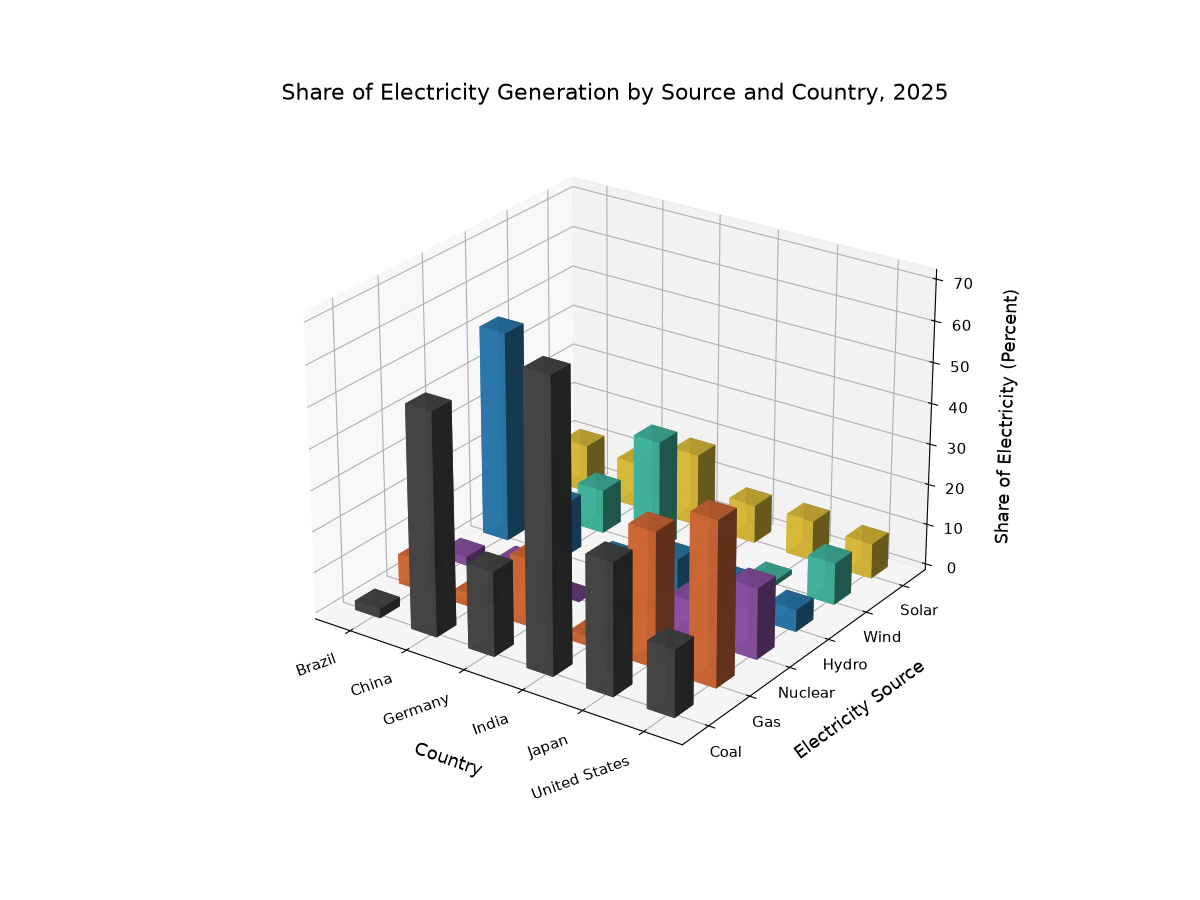

In [9]:
country_order = ['Brazil', 'China', 'Germany', 'India', 'Japan', 'United States']
source_order = ['Coal', 'Gas', 'Nuclear', 'Hydro', 'Wind', 'Solar']

# One hex color per electricity source
source_colors = {'Coal': '#4D4D4D', 'Gas': '#E8743B', 'Nuclear': '#9B59B6',
                 'Hydro': '#2E86C1', 'Wind': '#48C9B0', 'Solar': '#F4D03F'}

# Map each category to a numeric position on its axis
energy['x_pos'] = energy['country'].map({c: i for i, c in enumerate(country_order)})
energy['y_pos'] = energy['source'].map({s: i for i, s in enumerate(source_order)})

bar_width = 0.45
fig = plt.figure(figsize=(12, 9))
ax = plt.axes(projection='3d')

# Draw each bar separately, from the back of the view to the front,
# so Matplotlib layers the bars correctly
draw_order = energy.sort_values(['y_pos', 'x_pos'], ascending=[False, True])
for _, row in draw_order.iterrows():
    ax.bar3d(row['x_pos'] - bar_width / 2, row['y_pos'] - bar_width / 2, 0,
             bar_width, bar_width, row['share_of_electricity_pct'],
             color=source_colors[row['source']], alpha=0.9, shade=True)

ax.set_title('Share of Electricity Generation by Source and Country, 2025')
ax.set_xticks(range(len(country_order)))
ax.set_xticklabels(country_order, rotation=20, ha='right')
ax.set_yticks(range(len(source_order)))
ax.set_yticklabels(source_order)
ax.set_xlabel('Country', labelpad=22)
ax.set_ylabel('Electricity Source', labelpad=14)
ax.set_zlabel('Share of Electricity (Percent)', labelpad=12)
ax.view_init(elev=25, azim=-55)
plt.show()

**Conclusions:**

1. **Coal still dominates electricity generation in Asia's two largest economies.** Coal produced about 71 percent of India's electricity and about 54 percent of China's in 2025, so the two tallest dark gray bars belong to those countries. Japan also relied on coal for about 32 percent of its electricity.
2. **Each country has a distinct primary source.** Brazil generated about 52 percent of its electricity from hydropower, the largest hydro share in the group. Natural gas was the largest source in the United States (about 40 percent) and in Japan (about 33 percent), while wind was Germany's largest single source at about 27 percent.
3. **Germany leads the group in wind and solar combined.** Wind (27 percent) and solar (18 percent) together produced about 45 percent of Germany's electricity, even though the country produced no nuclear power in 2025 after closing its last reactors. Brazil follows with about 27 percent from wind and solar combined.
4. **Solar is the most evenly distributed source.** Solar bars are short but present in every country, ranging from about 9 to 18 percent, while coal, hydro, and nuclear vary widely from one country to the next. Nuclear is a major source only in the United States (about 17 percent) and Japan (about 9 percent).

## Part IV: Unity Tutorial Answers

The two physics screenshots (before and after pressing Play) and the screenshot of the population globe focused on the United States are uploaded separately with this notebook.

**Which parts of the country have some of the largest populations? Which parts have some of the lowest?**

The tallest and brightest bars on the globe cluster along the East Coast, especially in the Northeast corridor that runs from Boston through New York City, Philadelphia, Baltimore, and Washington, D.C. Other tall bars appear in Southern California around Los Angeles and San Diego, the San Francisco Bay Area, the Chicago area and the Great Lakes region, Florida, and the major Texas metropolitan areas of Houston, Dallas and Fort Worth, and San Antonio. The lowest populations appear across the Great Plains and the Mountain West, including Montana, Wyoming, the Dakotas, Nebraska, Nevada, Utah, and eastern Oregon, where the bars are short and scattered or missing. Alaska also shows very little population outside of the Anchorage area. Overall, the eastern half of the country is far more densely populated than the western interior, with the West Coast as the main exception.

**Do you feel that this visualization counts as virtual reality (VR)? Explain.**

I do not believe this visualization counts as true virtual reality. It is an interactive three-dimensional visualization: the globe can be rotated, zoomed, and explored, and the bars have real depth. However, it is displayed on a flat monitor and controlled with a mouse and keyboard, so the user looks at the virtual world through a window rather than being placed inside it. Virtual reality requires immersion, which usually means a head-mounted display that tracks head movement, fills the field of view, and creates a sense of presence. Without that immersion and head tracking, the experience is better described as a desktop 3D visualization. It could become VR if it were built for a headset.

**How do you feel this experience would differ with a head-mounted display, such as a Meta Quest or HTC Vive?**

With a head-mounted display, the globe would surround the viewer instead of sitting on a screen. The user could walk around the globe, lean in toward a city, or look up at the tallest population bars, and the stereoscopic depth would make differences in bar height much easier to judge than on a flat monitor. Hand controllers would replace the mouse and arrow keys, so rotating and zooming would feel more natural, like holding and turning a real object. The experience would be far more memorable and engaging. It would also bring some drawbacks: motion sickness during fast rotation, the cost of the hardware, reduced readability of small text labels, and the difficulty of taking notes or comparing exact numbers while wearing a headset.

## Part V: Extended Reality Visualization

**Visualization:** [Is the Nasdaq in Another Bubble? A Virtual Reality Tour of the Nasdaq](https://graphics.wsj.com/3d-nasdaq/), published by The Wall Street Journal and created by Roger Kenny and Ana Becker.

**What information is being displayed? Why did you pick it? What timeframe is being considered?**

The visualization turns the Nasdaq Composite Index into a three-dimensional line graph that the viewer rides like a roller coaster. The height of the track represents the value of the index, and the [width of the path represents the index's price-to-earnings ratio](https://graphics.wsj.com/3d-nasdaq/), so a narrower path means share prices are high relative to company earnings, a warning sign of a bubble. Major events and turning points are marked along the ride. It can be viewed on a desktop computer by clicking and dragging, on a phone by moving the device, or in virtual reality with a mobile viewer such as Google Cardboard, where the [viewer looks at buttons to activate them](https://www.journalism.co.uk/wsj-viscerally-emulate-nasdaq-highs-and-lows-with-virtual-reality/).

The timeframe covers 21 years of market history, [starting in 1994 at the beginning of the technology boom](https://www.journalism.co.uk/wsj-viscerally-emulate-nasdaq-highs-and-lows-with-virtual-reality/) and ending in April 2015, when the Nasdaq reached a record high for the first time since 2000. I picked this example because it shows that extended reality can make an ordinary financial line chart physical. Instead of reading a price chart, the viewer feels the steep climb of the late 1990s and the stomach-dropping fall of 2000, which matches the team's goal to ["viscerally emulate the experience of an investor."](https://www.journalism.co.uk/wsj-viscerally-emulate-nasdaq-highs-and-lows-with-virtual-reality/)

**Study the visualization and draw a couple conclusions.**

1. **Market growth is not steady.** The ride [bumps along through the 1990s, climbs steeply in 1999, and then falls rapidly when the dot-com bubble bursts in 2000](https://www.storybench.org/why-the-wsj-used-a-virtual-roller-coaster-ride-to-bring-stock-prices-to-life/). A second large drop follows during the 2008 recession. Long periods of slow growth can be erased quickly, and the index took about 15 years to return to its 2000 peak.
2. **A record price does not automatically mean a bubble.** The track is at nearly the same height in 2000 and in 2015, but the narrowing of the path, which reflects the price-to-earnings ratio, is far more severe around 2000. That comparison suggests that the 2015 high was supported by much stronger company earnings than the 2000 peak, so the market was not as overvalued even though the index value looked similar.

**Who would benefit from studying this visualization?**

Individual investors and retirement savers would benefit because the ride shows how quickly markets can rise and fall and why valuation matters as much as price. Finance and economics students could use it to understand the dot-com bubble, the 2008 financial crisis, and the meaning of the price-to-earnings ratio. Teachers and financial advisors could use it to explain risk to people who find traditional stock charts intimidating. Journalists, designers, and data visualization students would also benefit, because it is an early example of using virtual reality to tell a data story, and the team's notes about [users getting stuck and struggling with controls](https://www.journalism.co.uk/wsj-viscerally-emulate-nasdaq-highs-and-lows-with-virtual-reality/) offer lessons for designing immersive interfaces.

**What are your thoughts on data visualizations in extended reality? Do you think they are a good option to consider? What are some advantages and disadvantages?**

I think extended reality visualizations are a good option for specific situations, especially when the data is naturally spatial (such as maps, buildings, terrain, or molecular structures) or when the goal is to make an audience feel the scale of a story. They should support, not replace, traditional charts.

Advantages:

- Immersion and engagement make the information more memorable, especially for audiences who would skip a standard chart.
- Depth and true three-dimensional space let viewers explore complex or spatial data from any angle.
- Natural interaction through head movement and hand controllers can feel more intuitive than a mouse and keyboard.
- Augmented reality can place data directly in its real-world context, such as overlaying measurements on a construction site or a building.

Disadvantages:

- Headsets are expensive, and not every audience has access to the required hardware.
- Motion sickness, eye strain, and fatigue limit how long people can use the experience.
- Exact values are harder to read and compare in 3D because of perspective and occlusion, so precision can suffer.
- XR visualizations take more time, skill, and testing to build, and they are harder to share, print, and make accessible.
- A flashy experience can distract from the data if the immersive format does not add real insight.